# D1 — Frozen AraBERT-twitter: `[CLS]` vs. mean pooling → logistic regression

`aubmindlab/bert-base-arabertv02-twitter`, encoder frozen. Each tweet → `[CLS]` vector and attention-mask-weighted mean of the tokens →
StandardScaler → LogisticRegression (`class_weight="balanced"`, `C` picked on val) → threshold tuned on val (`fit_with_threshold`).
Fit on train only; test stays sealed.

In [1]:
import os
import sys

REPO = "Arabic-sarcasm"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q uv
!uv pip install --system emoji tashaphyne

Cloning into '/content/Arabic-sarcasm'...
remote: Enumerating objects: 98, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 98 (delta 45), reused 69 (delta 25), pack-reused 0 (from 0)
Receiving objects: 100% (98/98), 633.05 KiB | 1.56 MiB/s, done.
Resolving deltas: 100% (45/45), done.
/content/Arabic-sarcasm
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 43.6 MB/s eta 0:00:00
Using Python 3.13.15 environment at: /usr
Resolved 4 packages in 85ms
Prepared 3 packages in 27ms
Installed 3 packages in 3ms
 + emoji==2.16.0
 + pyarabic==0.6.15
 + tashaphyne==0.3.6


In [2]:
# arabert pins an old emoji (1.x, no Arabic names): install it without deps, then force emoji>=2.16.
# If you see a KeyError in emoji.demojize, restart the runtime once and re-run from the top.
%pip install -q --no-deps arabert
%pip install -q -U "emoji>=2.16" pyarabic sentencepiece protobuf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 1.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [3]:
import time

import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoModel, AutoTokenizer

from src.data import get_data
from src.evaluate import log_result, metrics, plot_results, save_predictions, show
from src.preprocess import build_pipeline
from src.train import fit_with_threshold, set_seed

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

/usr/local/lib/python3.13/dist-packages/tashaphyne/stemming.py:106: SyntaxWarning: invalid escape sequence '\w'
  self.token_pat = re.compile(u"[^\w\u064b-\u0652']+", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:274: SyntaxWarning: invalid escape sequence '\w'
  TOKEN_PATTERN = re.compile(u"([^\w\u0670\u064b-\u0652']+)", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:276: SyntaxWarning: invalid escape sequence '\w'
  TOKEN_PATTERN_SPLIT = re.compile(u"([\w\u0670\u064b-\u0652']+)", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:281: SyntaxWarning: invalid escape sequence '\s'
  ARABIC_STRING = re.compile(u"([^\u0600-\u0652%s%s%s\s\d])" \
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:1237: SyntaxWarning: invalid escape sequence '\s'
  u"(?<=\s(%s|%s))%s" % (WAW, YEH, FATHA), \
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:1450: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub(u"(?<=[

cuda


In [4]:
train, val, test, report = get_data()
y_train, y_val = train["sarcasm"].values, val["sarcasm"].values
print(f"train: {len(train)} | val: {len(val)}")

train: 10781 | val: 1255


In [5]:
BASE = ["html", "mentions", "hashtags"]
EMOJI = ["emoji"]
NORM = ["diacritics", "kashida", "letters", "elongation"]
LIGHT = ["light_stem"]
URLS = ["urls"]

COMBOS = {
    # same names / definitions as 02_baseline (so rows are comparable in results.csv)
    "base":                      BASE,
    "emoji":                     BASE + EMOJI,
    "norm":                      BASE + NORM,
    "light_stem":                BASE + LIGHT,
    "emoji + norm":              BASE + EMOJI + NORM,
    "emoji + light_stem":        BASE + EMOJI + LIGHT,
    "norm + light_stem":         BASE + NORM + LIGHT,
    "emoji + norm + light_stem": BASE + EMOJI + NORM + LIGHT,
    "urls kept":                 BASE,
    # added for PLMs: URLs -> <URL>, no stemming, AraBERT's own preprocessor
    "urls replaced":             BASE + URLS,
    "emoji + urls replaced":     BASE + URLS + EMOJI,
    "minimal":                   ["html", "urls", "mentions"],   # what 05_finetune uses
    "arabert":                   None,
}

In [6]:
def make_prep(steps):
    if steps is None:
        from arabert.preprocess import ArabertPreprocessor
        return ArabertPreprocessor(model_name="aubmindlab/bert-base-arabertv02-twitter").preprocess
    return build_pipeline(steps)


def prepare(frame, steps):
    prep = make_prep(steps)
    texts = [prep(tweet) for tweet in frame["tweet"]]
    return [t if t.strip() else raw for t, raw in zip(texts, frame["tweet"])]


try:
    make_prep(None)("هذا مثال 😂 @user #وسم_تجريبي http://t.co/x")   # fails here, not mid-run, if arabert is incompatible
except Exception as error:
    print("arabert preprocessing skipped:", error)
    COMBOS.pop("arabert")

print(list(COMBOS))
print("base       :", prepare(val.head(4), COMBOS["base"])[3][:100])
print("urls kept == base (BASE has no urls step), so those two rows are expected to match")

arabert preprocessing skipped: module 'emoji' has no attribute 'UNICODE_EMOJI'
['base', 'emoji', 'norm', 'light_stem', 'emoji + norm', 'emoji + light_stem', 'norm + light_stem', 'emoji + norm + light_stem', 'urls kept', 'urls replaced', 'emoji + urls replaced', 'minimal']
base       : "ريكي مارتن يخطب الرسام السوري جوان يوسفhttps://t.co/vm0NYjJIRF"
urls kept == base (BASE has no urls step), so those two rows are expected to match


In [7]:
def slug(name):
    return name.replace(" + ", "+").replace(" ", "_")

NAME = "aubmindlab/bert-base-arabertv02-twitter"
MAX_LEN, BATCH = 96, 64

tok = AutoTokenizer.from_pretrained(NAME)
encoder = AutoModel.from_pretrained(NAME).to(DEVICE).eval()
for p in encoder.parameters():
    p.requires_grad = False
HIDDEN = encoder.config.hidden_size
print("frozen parameters:", sum(p.numel() for p in encoder.parameters()))

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


frozen parameters: 135193344


In [8]:
@torch.no_grad()
def embed(texts):
    """[CLS] and mask-weighted mean of the last layer, in the original order."""
    order = np.argsort([len(t) for t in texts])
    cls = np.zeros((len(texts), HIDDEN), dtype=np.float32)
    mean = np.zeros((len(texts), HIDDEN), dtype=np.float32)
    for i in range(0, len(texts), BATCH):
        idx = order[i:i + BATCH]
        enc = tok([texts[j] for j in idx], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            hidden = encoder(**enc).last_hidden_state.float()
        mask = enc["attention_mask"].unsqueeze(-1).float()
        cls[idx] = hidden[:, 0].cpu().numpy()
        mean[idx] = ((hidden * mask).sum(1) / mask.sum(1).clamp(min=1)).cpu().numpy()
    return cls, mean


def fit_lr(X_train, X_val):
    best = None
    for C in (0.01, 0.1, 1.0):
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=C, class_weight="balanced", max_iter=2000)
        )
        threshold, seconds = fit_with_threshold(model, X_train, y_train, X_val, y_val)
        proba = model.predict_proba(X_val)[:, 1]
        scores = metrics(y_val, proba, threshold)
        if best is None or scores["f1"] > best["scores"]["f1"]:
            best = dict(C=C, model=model, threshold=threshold, seconds=seconds, scores=scores, proba=proba)
    return best

In [9]:
def run(combos):
    rows, seen = [], {}

    for name, steps in combos.items():
        train_texts, val_texts = prepare(train, steps), prepare(val, steps)
        h = hash((tuple(train_texts), tuple(val_texts)))

        if h not in seen:                       # identical inputs (base / urls kept) are computed once
            tr, va = embed(train_texts), embed(val_texts)
            seen[h] = {p: fit_lr(tr[k], va[k]) for k, p in enumerate(("cls", "mean"))}

        for pooling, best in seen[h].items():
            model_name = f"arabert_frozen_{pooling}_lr"

            log_result(
                model=model_name,
                preprocessing=name,
                seed=42,
                threshold=best["threshold"],
                train_time=best["seconds"],
                trained_params=best["model"][-1].coef_.size + 1,
                **{f"val_{k}": v for k, v in best["scores"].items()}
            )
            save_predictions(f"{model_name}_{slug(name)}", 42, val["id"], y_val, best["proba"], best["threshold"])

            show(f"{pooling} C={best['C']} | {name}", best["scores"], best["threshold"], best["seconds"])
            rows.append({"pooling": pooling, "preprocessing": name, "C": best["C"],
                         "threshold": best["threshold"], **best["scores"]})

    return pd.DataFrame(rows)

table = run(COMBOS)

cls C=0.01 | base            f1=0.6085  pr_auc=0.6036  threshold=0.58  2s
mean C=0.01 | base           f1=0.6207  pr_auc=0.6425  threshold=0.58  2s
cls C=0.01 | emoji           f1=0.6123  pr_auc=0.6174  threshold=0.57  1s
mean C=0.01 | emoji          f1=0.6298  pr_auc=0.6329  threshold=0.68  1s
cls C=0.01 | norm            f1=0.6340  pr_auc=0.6100  threshold=0.58  1s
mean C=0.01 | norm           f1=0.6308  pr_auc=0.6524  threshold=0.55  1s
cls C=0.01 | light_stem      f1=0.5788  pr_auc=0.5341  threshold=0.60  1s
mean C=0.01 | light_stem     f1=0.5844  pr_auc=0.5524  threshold=0.65  1s
cls C=0.01 | emoji + norm    f1=0.6308  pr_auc=0.6145  threshold=0.59  2s
mean C=0.01 | emoji + norm   f1=0.6280  pr_auc=0.6434  threshold=0.62  1s
cls C=0.01 | emoji + light_stem f1=0.5729  pr_auc=0.5467  threshold=0.54  1s
mean C=0.01 | emoji + light_stem f1=0.5786  pr_auc=0.5468  threshold=0.67  1s
cls C=0.01 | norm + light_stem f1=0.5813  pr_auc=0.5608  threshold=0.65  1s
mean C=0.01 | norm + light_st

In [10]:
table.pivot(index="preprocessing", columns="pooling", values="f1").round(4)

pooling,cls,mean
preprocessing,,
base,0.6085,0.6207
emoji,0.6123,0.6298
emoji + light_stem,0.5729,0.5786
emoji + norm,0.6308,0.6280
emoji + norm + light_stem,0.5891,0.5864
emoji + urls replaced,0.6253,0.6384
light_stem,0.5788,0.5844
minimal,0.6420,0.6337
norm,0.6340,0.6308


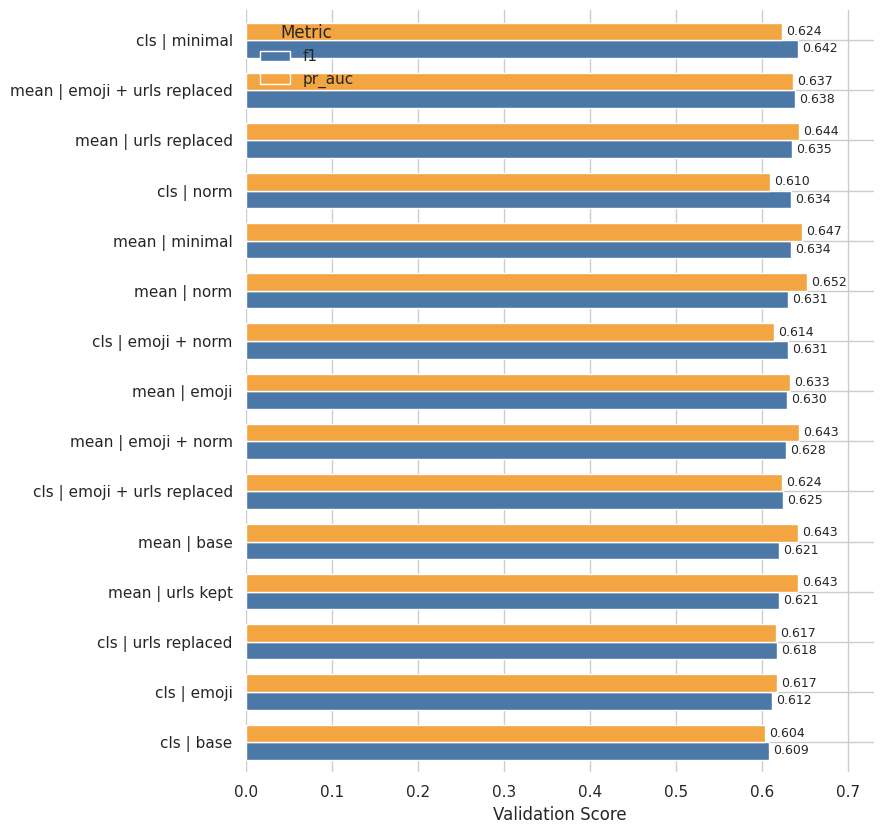

In [11]:
summary = table.assign(name=table["pooling"] + " | " + table["preprocessing"]).set_index("name")
plot_results(summary.nlargest(15, "f1"))